# Customer Retention & LTV Optimization: Diagnostic Analysis

**Business question.** Monthly logo churn sits near 4.6% and ~1 in 3 new customers leave inside six months.
Where is revenue leaking, which customers are worth acquiring, and what is the cheapest lever to pull?

**Inputs.** Query outputs from `sql/analytics_queries.sql` (all heavy aggregation happens in SQL, in `data/processed/`).
**Outputs.** Figures in `assets/`, headline numbers in `results/metrics.json`, extracts for the dashboard in `dashboard/data/`.

| Section | Question |
|---|---|
| 1. KPI overview | How healthy is recurring revenue? |
| 2. Cohort retention | Are newer cohorts better or worse than older ones? |
| 3. Unit economics | Which channels pay back? |
| 4. RFM segmentation | Which *current* customers are slipping away? |
| 5. Churn drivers | What early signals predict a customer leaving? |
| 6. Business case | What is the ROI of acting on it? |

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()
PROC, ASSETS, RESULTS, DASH = ROOT/"data/processed", ROOT/"assets", ROOT/"results", ROOT/"dashboard/data"
for p in (ASSETS, RESULTS, DASH): p.mkdir(exist_ok=True, parents=True)

# Plot style: one accent hue + validated categorical order (blue, orange, aqua, yellow)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8985"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "font.size": 10})
GM = 0.80                    # gross margin assumption (documented in the BRD)
metrics = {}                 # headline numbers, written to results/metrics.json at the end

kpi   = pd.read_csv(PROC/"kpi_monthly.csv", parse_dates=["month"])
seg   = pd.read_csv(PROC/"kpi_monthly_segmented.csv", parse_dates=["month"])
coh   = pd.read_csv(PROC/"cohort_retention.csv", parse_dates=["cohort_month"])
ue_ch = pd.read_csv(PROC/"unit_economics_by_channel.csv")
ue_pl = pd.read_csv(PROC/"unit_economics_by_plan.csv")
onb   = pd.read_csv(PROC/"onboarding_impact.csv")
feat  = pd.read_csv(PROC/"churn_features.csv")
rfm   = pd.read_csv(PROC/"rfm_base.csv")
print({k: len(v) for k, v in dict(kpi=kpi, seg=seg, coh=coh, feat=feat, rfm=rfm).items()})

{'kpi': 24, 'seg': 288, 'coh': 300, 'feat': 6787, 'rfm': 6203}


## 1. KPI overview

The monthly MRR bridge decomposes the change in recurring revenue into **new**, **expansion**, **contraction** and **churned** MRR.
Churn is measured only for months where it can be observed (the last month is the snapshot).

{
 "snapshot_month": "2025-12-01",
 "mrr": 1103797.0,
 "arr": 13245564.0,
 "active_customers": 6203,
 "arpa": 177.95,
 "mrr_growth_12m_pct": 141.7,
 "avg_logo_churn_pct_6m": 4.58,
 "avg_nrr_pct_6m": 98.7,
 "churned_mrr_6m": 160385.0
}


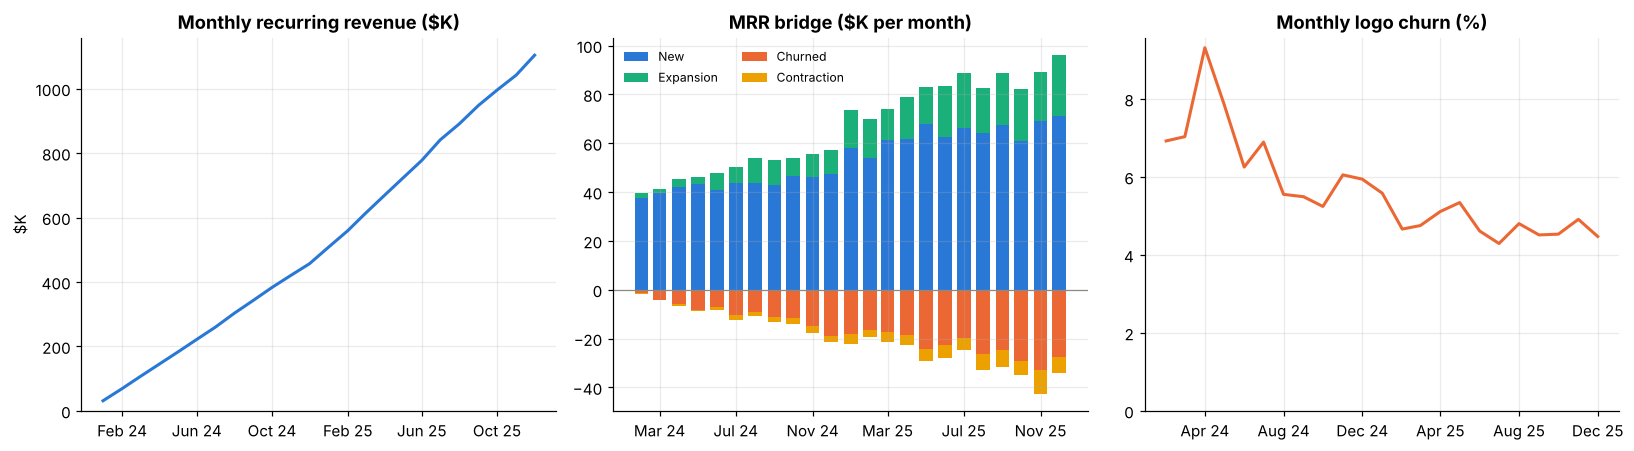

In [2]:
last, prev = kpi.iloc[-1], kpi.iloc[-2]
t6 = kpi.iloc[-7:-1]                                  # trailing 6 full months before snapshot
mrr_growth_12m = kpi.iloc[-1].mrr / kpi.iloc[-13].mrr - 1
metrics.update(
    snapshot_month=str(last.month.date()),
    mrr=float(last.mrr), arr=float(last.mrr*12), active_customers=int(last.active_customers),
    arpa=float(last.arpa), mrr_growth_12m_pct=round(100*mrr_growth_12m, 1),
    avg_logo_churn_pct_6m=round(float(kpi.iloc[-6:].logo_churn_pct.mean()), 2),
    avg_nrr_pct_6m=round(float(kpi.iloc[-6:].nrr_pct.mean()), 2),
    churned_mrr_6m=float(kpi.iloc[-6:].churned_mrr.sum()),
)
print(json.dumps({k: metrics[k] for k in list(metrics)}, indent=1))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(kpi.month, kpi.mrr/1e3, color=BLUE, lw=2)
ax[0].set(title="Monthly recurring revenue ($K)", ylabel="$K"); ax[0].set_ylim(0)
b = kpi.iloc[1:]
w = 22
ax[1].bar(b.month, b.new_mrr/1e3, w, color=BLUE, label="New")
ax[1].bar(b.month, b.expansion_mrr/1e3, w, bottom=b.new_mrr/1e3, color=AQUA, label="Expansion")
ax[1].bar(b.month, -b.churned_mrr/1e3, w, color=ORANGE, label="Churned")
ax[1].bar(b.month, -b.contraction_mrr/1e3, w, bottom=-b.churned_mrr/1e3, color=YELLOW, label="Contraction")
ax[1].axhline(0, color=GREY, lw=.8); ax[1].set(title="MRR bridge ($K per month)"); ax[1].legend(ncol=2, fontsize=8, frameon=False)
ax[2].plot(b.month, b.logo_churn_pct, color=ORANGE, lw=2, label="Logo churn %")
ax[2].set(title="Monthly logo churn (%)"); ax[2].set_ylim(0)
for a in ax: a.xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); a.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
plt.tight_layout(); plt.savefig(ASSETS/"01_mrr_overview.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading the chart.** New business is healthy, but every month roughly 4-5% of logos and ~2-3% of MRR walk out the door,
and expansion only just offsets contraction plus churn (NRR hovers around 98-99% *per month*). Growth is being bought with
acquisition rather than retained.

## 2. Cohort retention

Each row is a signup-month cohort; each column is months since signup. Early-life churn is steep (months 0 to 3), then flattens.

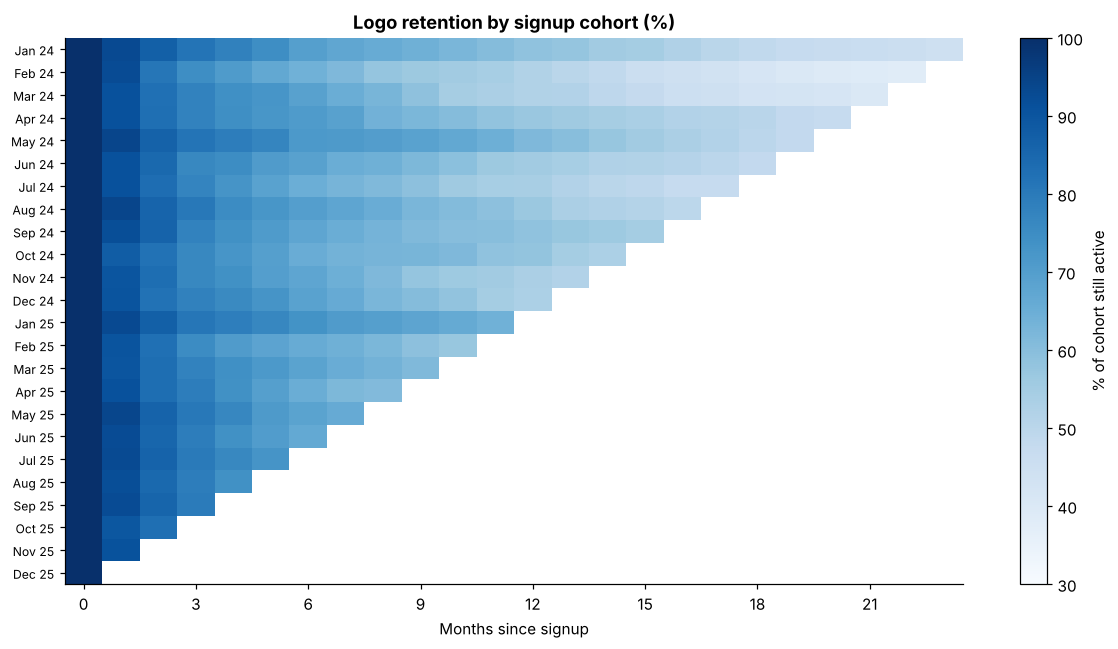

{'retention_m3_pct': 77.9, 'retention_m6_pct': 68.4, 'retention_m12_pct': 55.8}


In [3]:
piv = coh.pivot(index="cohort_month", columns="months_since_signup", values="logo_retention_pct")
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(piv.values, cmap="Blues", vmin=30, vmax=100, aspect="auto")
ax.set_xticks(range(0, piv.shape[1], 3)); ax.set_xticklabels(piv.columns[::3])
ax.set_yticks(range(len(piv))); ax.set_yticklabels([d.strftime("%b %y") for d in piv.index], fontsize=8)
ax.set(title="Logo retention by signup cohort (%)", xlabel="Months since signup"); ax.grid(False)
plt.colorbar(im, ax=ax, label="% of cohort still active")
plt.tight_layout(); plt.savefig(ASSETS/"02_cohort_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

def ret_at(m):
    s = coh[(coh.months_since_signup == m) & (coh.cohort_month <= "2025-03-01")]
    return float((s.active_customers.sum() / s.cohort_size.sum()) * 100)
metrics.update(retention_m3_pct=round(ret_at(3), 1), retention_m6_pct=round(ret_at(6), 1), retention_m12_pct=round(ret_at(12), 1))
print({k: metrics[k] for k in ("retention_m3_pct", "retention_m6_pct", "retention_m12_pct")})

## 3. Unit economics by acquisition channel

`LTV = ARPA x gross margin / monthly churn`, `CAC = channel spend / customers acquired`. Both are computed in SQL.
A common rule of thumb is LTV:CAC >= 3 and CAC payback < 12 months.

,channel,customers_acquired,total_spend,cac,arpa,monthly_churn_pct,ltv,ltv_to_cac,cac_payback_months
0,referral,1791,783261.0,437.33,170.30,3.71,3677.0,8.41,3.2
1,organic_search,2400,970816.0,404.51,145.05,4.86,2390.0,5.91,3.5
2,outbound,970,2874058.0,2962.95,335.94,3.07,8747.0,2.95,11.0
3,paid_search,2376,2160179.0,909.17,131.64,5.62,1874.0,2.06,8.6
4,paid_social,2256,2668304.0,1182.76,118.32,7.33,1292.0,1.09,12.5


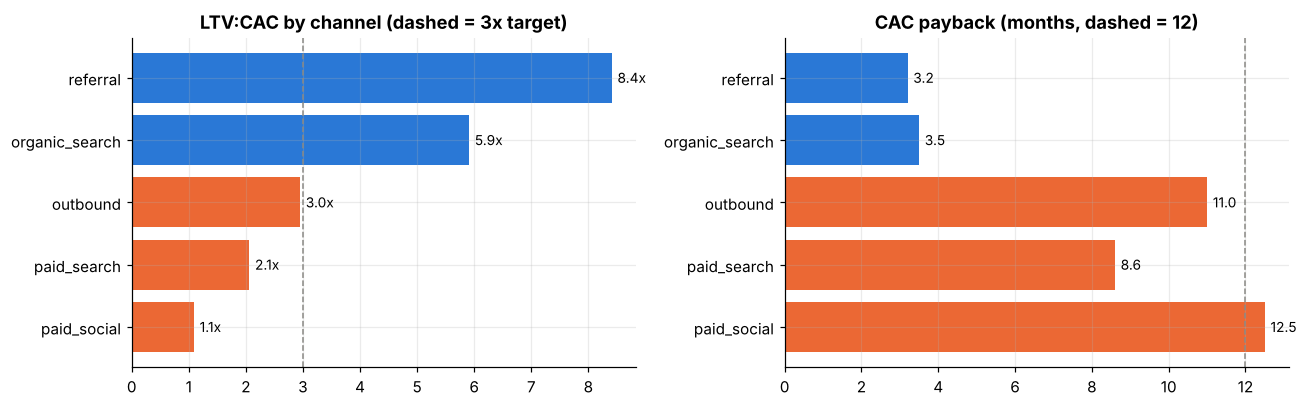

In [4]:
display(ue_ch)
ue = ue_ch.sort_values("ltv_to_cac")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
cols = [ORANGE if v < 3 else BLUE for v in ue.ltv_to_cac]
ax[0].barh(ue.channel, ue.ltv_to_cac, color=cols); ax[0].axvline(3, color=GREY, ls="--", lw=1)
ax[0].set(title="LTV:CAC by channel (dashed = 3x target)")
for i, v in enumerate(ue.ltv_to_cac): ax[0].text(v + .1, i, f"{v:.1f}x", va="center", fontsize=9)
ax[1].barh(ue.channel, ue.cac_payback_months, color=cols); ax[1].axvline(12, color=GREY, ls="--", lw=1)
ax[1].set(title="CAC payback (months, dashed = 12)")
for i, v in enumerate(ue.cac_payback_months): ax[1].text(v + .15, i, f"{v:.1f}", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(ASSETS/"03_unit_economics.png", dpi=150, bbox_inches="tight"); plt.show()

metrics["unit_economics"] = ue_ch.to_dict(orient="records")
metrics["plan_economics"] = ue_pl.to_dict(orient="records")
total_spend = ue_ch.total_spend.sum()
metrics["blended_cac"] = round(float(total_spend / ue_ch.customers_acquired.sum()), 0)

**Takeaway.** Referral and organic return roughly 6-8x their cost. Paid social returns barely 1x and takes about a year to pay back:
it brings in the lowest-ARPA, highest-churn customers. Outbound is acceptable only because its enterprise accounts are large.

## 4. RFM segmentation of the active base

Scores come from `NTILE(5)` in SQL (5 = best). Segments combine recency and frequency; monetary value separates
high-value at-risk accounts (worth a human call) from hibernating low-value ones (automated win-back).

,customers,mrr,avg_recency_days,avg_logins_3m,pct_of_mrr
segment,,,,,
Champions,1471,436429.0,8.9,91.5,39.5
Loyal,2281,444369.0,15.3,58.5,40.3
Needs attention,940,104710.0,18.9,32.8,9.5
At risk (high value),524,48226.0,25.0,26.8,4.4
Hibernating,987,70063.0,23.9,19.4,6.3


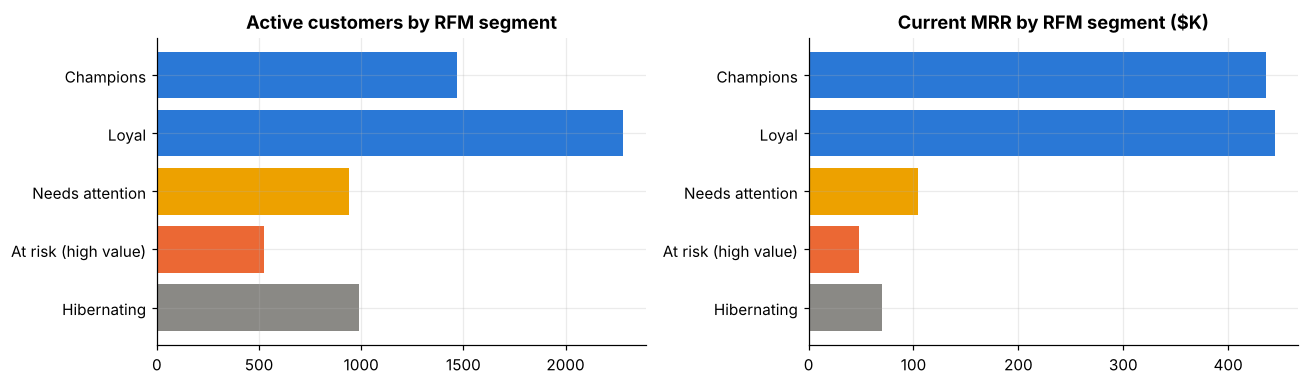

In [5]:
rfm["rf"] = (rfm.r_score + rfm.f_score) / 2
def segment(r):
    if r.rf >= 4:   return "Champions"
    if r.rf >= 3:   return "Loyal"
    if r.rf > 2:    return "Needs attention"
    return "At risk (high value)" if r.m_score >= 3 else "Hibernating"
rfm["segment"] = rfm.apply(segment, axis=1)
order = ["Champions", "Loyal", "Needs attention", "At risk (high value)", "Hibernating"]
seg_sum = (rfm.groupby("segment").agg(customers=("customer_id", "count"), mrr=("current_mrr", "sum"),
           avg_recency_days=("recency_days", "mean"), avg_logins_3m=("frequency_3m", "mean"))
           .reindex(order).round(1))
seg_sum["pct_of_mrr"] = (100 * seg_sum.mrr / seg_sum.mrr.sum()).round(1)
display(seg_sum)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
cmap = {"Champions": BLUE, "Loyal": BLUE, "Needs attention": YELLOW, "At risk (high value)": ORANGE, "Hibernating": GREY}
ax[0].barh(seg_sum.index[::-1], seg_sum.customers[::-1], color=[cmap[s] for s in seg_sum.index[::-1]])
ax[0].set(title="Active customers by RFM segment")
ax[1].barh(seg_sum.index[::-1], seg_sum.mrr[::-1]/1e3, color=[cmap[s] for s in seg_sum.index[::-1]])
ax[1].set(title="Current MRR by RFM segment ($K)")
plt.tight_layout(); plt.savefig(ASSETS/"04_rfm_segments.png", dpi=150, bbox_inches="tight"); plt.show()

at_risk = seg_sum.loc[["At risk (high value)", "Hibernating", "Needs attention"]]
metrics["rfm"] = seg_sum.reset_index().to_dict(orient="records")
metrics["at_risk_mrr"] = float(seg_sum.loc["At risk (high value)", "mrr"])
metrics["at_risk_customers"] = int(seg_sum.loc["At risk (high value)", "customers"])
metrics["at_risk_pct_mrr"] = float(seg_sum.loc["At risk (high value)", "pct_of_mrr"])
rfm[["customer_id", "region", "acquisition_channel", "current_plan", "current_mrr", "recency_days",
     "frequency_3m", "r_score", "f_score", "m_score", "segment"]].to_csv(DASH/"rfm_segments.csv", index=False)

## 5. What drives early churn?

**Target:** churned within 6 months of signup (customers with >= 7 months of history, `n = 6,787`).
**Features** use only the first billing month plus onboarding timing, so the model could be used *at day 30* to flag risk.

### 5a. Onboarding speed vs. churn

,customers,churn_6m
onboarding_bucket,,
Within 3 days,1596,12.5
4-14 days,2804,28.0
15+ days,859,43.0
Never completed,1528,53.5


6m churn: within 3 days 12.5% vs everyone else 38.0%  ->  RR = 3.05 (95% CI 2.66-3.49), chi2 p = 2.6e-81


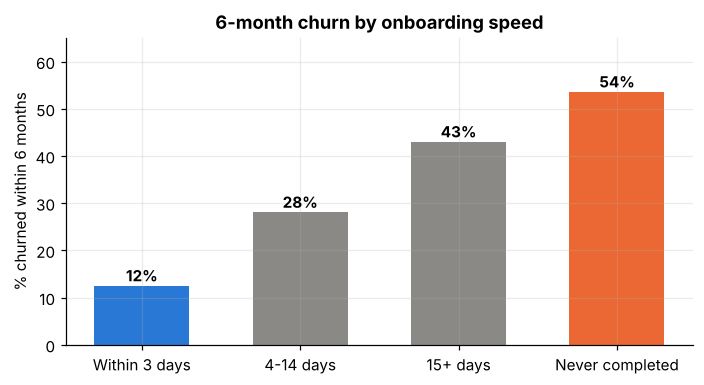

In [6]:
feat["onboarding_bucket"] = np.select(
    [feat.onboarding_never == 1, feat.onboarding_days <= 3, feat.onboarding_days <= 14],
    ["Never completed", "Within 3 days", "4-14 days"], "15+ days")
tab = feat.groupby("onboarding_bucket").agg(customers=("churned_6m", "size"), churn_6m=("churned_6m", "mean"))
tab = tab.reindex(["Within 3 days", "4-14 days", "15+ days", "Never completed"])
display((tab.assign(churn_6m=(100*tab.churn_6m).round(1))))

fast = feat[feat.onboarded_within_3d == 1]; slow = feat[feat.onboarded_within_3d == 0]
p1, p0 = fast.churned_6m.mean(), slow.churned_6m.mean()
rr = p0 / p1
# 95% CI for relative risk (log method)
se = np.sqrt((1-p0)/(p0*len(slow)) + (1-p1)/(p1*len(fast)))
rr_lo, rr_hi = np.exp(np.log(rr) - 1.96*se), np.exp(np.log(rr) + 1.96*se)
chi2, pval, *_ = stats.chi2_contingency(pd.crosstab(feat.onboarded_within_3d, feat.churned_6m))
print(f"6m churn: within 3 days {p1:.1%} vs everyone else {p0:.1%}  ->  RR = {rr:.2f} (95% CI {rr_lo:.2f}-{rr_hi:.2f}), chi2 p = {pval:.1e}")
metrics.update(churn6m_fast=round(100*p1, 1), churn6m_slow=round(100*p0, 1), rr_onboarding=round(rr, 2),
               rr_lo=round(rr_lo, 2), rr_hi=round(rr_hi, 2), pct_fast_onboarding=round(100*feat.onboarded_within_3d.mean(), 1),
               churn6m_overall=round(100*feat.churned_6m.mean(), 1), n_model=int(len(feat)))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(tab.index, 100*tab.churn_6m, color=[BLUE, GREY, GREY, ORANGE], width=.6)
for i, v in enumerate(100*tab.churn_6m): ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=10, fontweight="bold")
ax.set(title="6-month churn by onboarding speed", ylabel="% churned within 6 months"); ax.set_ylim(0, 65)
plt.tight_layout(); plt.savefig(ASSETS/"05_onboarding_churn.png", dpi=150, bbox_inches="tight"); plt.show()

### 5b. Interpretable model: logistic regression (odds ratios)

Continuous features are standardised so each odds ratio reads "per 1 SD". Reference levels: 4-14 day onboarding, Starter, paid search, North America.

In [7]:
feat["logins_m1_log"] = np.log1p(feat.logins_m1)
y = feat.churned_6m
X_raw = feat[["onboarding_bucket", "logins_m1_log", "features_m1", "plan_at_signup", "acquisition_channel", "region"]]
Xtr_raw, Xte_raw, ytr, yte = train_test_split(X_raw, y, test_size=.25, stratify=y, random_state=42)

def design(df, ref_cols):
    d = pd.get_dummies(df, columns=["onboarding_bucket", "plan_at_signup", "acquisition_channel", "region"], dtype=float)
    d = d.drop(columns=ref_cols)
    return d
refs = ["onboarding_bucket_4-14 days", "plan_at_signup_Starter", "acquisition_channel_paid_search", "region_North America"]
Dtr, Dte = design(Xtr_raw, refs), design(Xte_raw, refs)
mu, sd = Dtr[["logins_m1_log", "features_m1"]].mean(), Dtr[["logins_m1_log", "features_m1"]].std()
for D in (Dtr, Dte): D[["logins_m1_log", "features_m1"]] = (D[["logins_m1_log", "features_m1"]] - mu) / sd
logit = sm.Logit(ytr, sm.add_constant(Dtr)).fit(disp=0)
ci = logit.conf_int()
orr = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]), "p": logit.pvalues}).drop("const")
display(orr.round(3).sort_values("odds_ratio", ascending=False))

p_logit = logit.predict(sm.add_constant(Dte, has_constant="add"))
auc_logit = roc_auc_score(yte, p_logit)
print(f"Logistic regression hold-out AUC = {auc_logit:.3f}")
metrics["auc_logit"] = round(float(auc_logit), 3)
metrics["odds_ratios"] = orr.round(3).reset_index().rename(columns={"index": "feature"}).to_dict(orient="records")

,odds_ratio,ci_low,ci_high,p
onboarding_bucket_Never completed,2.951,2.521,3.454,0.000
onboarding_bucket_15+ days,1.932,1.594,2.341,0.000
acquisition_channel_paid_social,1.405,1.177,1.678,0.000
region_LATAM,1.060,0.831,1.352,0.639
region_APAC,1.056,0.882,1.263,0.555
region_EMEA,0.974,0.837,1.135,0.739
features_m1,0.969,0.900,1.043,0.408
acquisition_channel_outbound,0.844,0.634,1.124,0.246
acquisition_channel_organic_search,0.802,0.669,0.961,0.017
logins_m1_log,0.796,0.718,0.882,0.000


Logistic regression hold-out AUC = 0.757


### 5c. Non-linear check: random forest + permutation importance

Permutation importance is computed on **raw columns** of the hold-out set (drop in AUC when a column is shuffled), so
one-hot dummies do not dilute categorical drivers.

Random forest hold-out AUC = 0.753


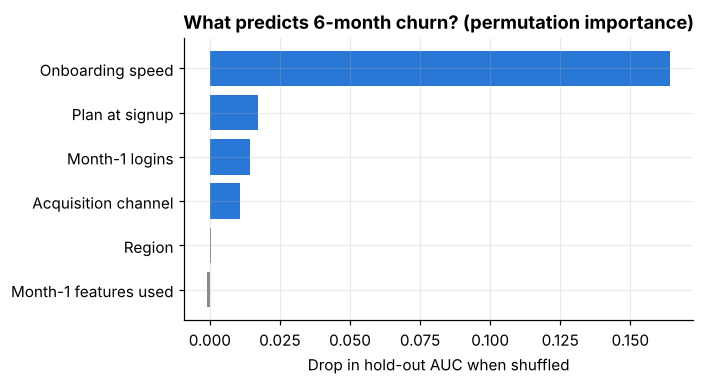

              precision    recall  f1-score   support

    retained      0.731     0.927     0.817      1154
     churned      0.639     0.274     0.384       543

    accuracy                          0.718      1697
   macro avg      0.685     0.601     0.601      1697
weighted avg      0.702     0.718     0.679      1697

Top-decile lift: 2.13x


In [8]:
cat = ["onboarding_bucket", "plan_at_signup", "acquisition_channel", "region"]
pipe = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat)], remainder="passthrough")),
                 ("rf", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=30, n_jobs=-1, random_state=42))])
pipe.fit(Xtr_raw, ytr)
p_rf = pipe.predict_proba(Xte_raw)[:, 1]
auc_rf = roc_auc_score(yte, p_rf)
print(f"Random forest hold-out AUC = {auc_rf:.3f}")

pi = permutation_importance(pipe, Xte_raw, yte, scoring="roc_auc", n_repeats=10, random_state=42)
imp = pd.Series(pi.importances_mean, index=Xte_raw.columns).sort_values()
names = {"onboarding_bucket": "Onboarding speed", "logins_m1_log": "Month-1 logins", "features_m1": "Month-1 features used",
         "plan_at_signup": "Plan at signup", "acquisition_channel": "Acquisition channel", "region": "Region"}
imp.index = [names[i] for i in imp.index]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(imp.index, imp.values, color=[BLUE if v > 0.01 else GREY for v in imp.values])
ax.set(title="What predicts 6-month churn? (permutation importance)", xlabel="Drop in hold-out AUC when shuffled")
plt.tight_layout(); plt.savefig(ASSETS/"06_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

thr = 0.5
print(classification_report(yte, (p_rf >= thr).astype(int), target_names=["retained", "churned"], digits=3))
# lift: churn rate among top-decile risk scores vs base
top = pd.DataFrame({"y": yte.values, "p": p_rf}).sort_values("p", ascending=False)
lift10 = top.head(int(len(top)*.1)).y.mean() / top.y.mean()
print(f"Top-decile lift: {lift10:.2f}x")
metrics.update(auc_rf=round(float(auc_rf), 3), top_decile_lift=round(float(lift10), 2),
               feature_importance=imp.round(4).sort_values(ascending=False).to_dict())
imp.sort_values(ascending=False).round(4).rename("auc_drop").reset_index().rename(columns={"index": "feature"}).to_csv(DASH/"feature_importance.csv", index=False)

**Reading the model.** Onboarding speed is by far the strongest early-warning signal. Plan, month-1 logins and acquisition channel
add smaller but real signal (e.g. paid-social customers churn more at equal engagement); region carries essentially none.
Both models reach a similar AUC (~0.75), so the simpler logistic model is preferable for explanation and for production scoring.

> **Causation caveat.** Fast onboarders are likely more motivated to begin with, and the model only controls for the engagement it can
> *observe* (month-1 usage). The adjusted estimate therefore still overstates what a new onboarding programme would achieve.
> The business case below applies an explicit **50% haircut** to it, shows sensitivity down to 25%, and recommends a randomised pilot
> (see the companion A/B-testing project for how to size and read one) before full roll-out.

## 6. Business case

### 6a. Onboarding programme

Counterfactual: move a share of customers who currently miss the 3-day window into a guided onboarding programme.
The risk reduction per converted customer comes from the logistic model (everything else held constant), then a **50% haircut**
is applied because unobserved motivation inflates any observational estimate.

In [9]:
# ---- adjusted effect: predicted churn if each non-fast customer were instead "Within 3 days"
full_X = design(X_raw, refs).copy()
full_X[["logins_m1_log", "features_m1"]] = (full_X[["logins_m1_log", "features_m1"]] - mu) / sd
slow_idx = feat.index[feat.onboarded_within_3d == 0]
actual = sm.add_constant(full_X.loc[slow_idx], has_constant="add")
cf = actual.copy()
for c in [c for c in cf.columns if c.startswith("onboarding_bucket_")]: cf[c] = 0.0
cf["onboarding_bucket_Within 3 days"] = 1.0
delta_adj = float((logit.predict(actual) - logit.predict(cf[actual.columns])).mean())
delta_raw = float(p0 - p1)
print(f"Per converted customer: raw gap = {delta_raw:.1%}, covariate-adjusted = {delta_adj:.1%}")

# ---- annual volumes (2025 signups) and scenario assumptions
cust_2025 = int(kpi[kpi.month.dt.year == 2025].new_customers.sum())
share_slow = 1 - feat.onboarded_within_3d.mean()
arpa_new = float(feat.merge(pd.read_csv(ROOT/"data/raw/invoices.csv"), on="customer_id").query("plan == plan_at_signup").mrr.mean())
A = dict(share_converted=0.25, cost_per_enrolled=40.0, months_of_value=12, gross_margin=GM, effect_haircut=0.5)
enrolled = cust_2025 * share_slow * A["share_converted"]
retained = enrolled * delta_adj * A["effect_haircut"]
value = retained * arpa_new * A["gross_margin"] * A["months_of_value"]
cost = enrolled * A["cost_per_enrolled"]
roi = (value - cost) / cost
pp_reduction = 100 * retained / cust_2025
print(f"2025 signups={cust_2025:,}; slow share={share_slow:.0%}; enrolled={enrolled:,.0f}; retained={retained:,.0f} customers")
print(f"Gross profit retained (12m)=${value:,.0f}; programme cost=${cost:,.0f}; ROI={roi:.1f}x; 6m churn reduced by {pp_reduction:.1f} pts across all new customers")
metrics["onboarding_scenario"] = dict(assumptions=A, delta_adjusted_pp=round(100*delta_adj, 1), delta_raw_pp=round(100*delta_raw, 1),
    signups_2025=cust_2025, share_not_fast=round(100*share_slow, 1), enrolled=round(enrolled), retained_customers=round(retained),
    arpa_new=round(arpa_new, 2), gross_profit_retained=round(value), program_cost=round(cost), roi_multiple=round(roi, 1),
    six_month_churn_reduction_pp=round(pp_reduction, 1))

# sensitivity: what if the true effect is only a fraction of the covariate-adjusted estimate? (base case = 50%)
sens = pd.DataFrame({f"{int(h*100)}% of est. effect": [((cust_2025*share_slow*s*delta_adj*h*arpa_new*GM*12) - cust_2025*share_slow*s*A["cost_per_enrolled"]) / 1e3
        for s in (0.15, 0.25, 0.40)] for h in (1.0, 0.5, 0.25)}, index=["15% enrolled", "25% enrolled", "40% enrolled"])
print("\nNet 12m gross profit ($K) under haircuts to the effect size:"); display(sens.round(0))
metrics["onboarding_sensitivity_k"] = sens.round(0).to_dict()

Per converted customer: raw gap = 25.5%, covariate-adjusted = 23.7%
2025 signups=5,837; slow share=76%; enrolled=1,116; retained=132 customers
Gross profit retained (12m)=$184,923; programme cost=$44,644; ROI=3.1x; 6m churn reduced by 2.3 pts across all new customers

Net 12m gross profit ($K) under haircuts to the effect size:


,100% of est. effect,50% of est. effect,25% of est. effect
15% enrolled,195.0,84.0,29.0
25% enrolled,325.0,140.0,48.0
40% enrolled,520.0,224.0,77.0


### 6b. Channel reallocation

In [10]:
spend = pd.read_csv(ROOT/"data/raw/marketing_spend.csv", parse_dates=["spend_month"])
s25 = spend[spend.spend_month.dt.year == 2025].groupby("channel").spend.sum()
move = 0.20 * s25["paid_social"]
ps, rf_ = ue_ch.set_index("channel").loc["paid_social"], ue_ch.set_index("channel").loc["referral"]
EFF = 0.5   # marginal referral efficiency vs. historical average (diminishing returns assumption)
lost = move / ps.cac * ps.ltv
gained = move / (rf_.cac / EFF) * rf_.ltv
print(f"Move ${move:,.0f} (20% of 2025 paid-social) -> referral at {EFF:.0%} efficiency")
print(f"  lifetime gross profit lost on paid social : ${lost:,.0f}")
print(f"  lifetime gross profit gained on referral  : ${gained:,.0f}   (net ${gained-lost:,.0f})")
metrics["reallocation"] = dict(moved_spend=round(float(move)), efficiency_haircut=EFF, ltv_lost=round(float(lost)),
                               ltv_gained=round(float(gained)), net_ltv=round(float(gained-lost)))

Move $321,509 (20% of 2025 paid-social) -> referral at 50% efficiency
  lifetime gross profit lost on paid social : $351,204
  lifetime gross profit gained on referral  : $1,351,598   (net $1,000,394)


### 6c. Win back at-risk accounts

In [11]:
at_mrr = metrics["at_risk_mrr"]
for save in (0.10, 0.20, 0.30):
    print(f"Saving {save:.0%} of at-risk MRR protects ${at_mrr*save*12:,.0f} of annual revenue")
metrics["at_risk_save_20pct_annual"] = round(at_mrr * 0.20 * 12)

Saving 10% of at-risk MRR protects $57,871 of annual revenue
Saving 20% of at-risk MRR protects $115,742 of annual revenue
Saving 30% of at-risk MRR protects $173,614 of annual revenue


## 7. Persist results for the dashboard, deck and README

In [12]:
# dashboard extracts (long, tidy files are Tableau / Power BI friendly)
kpi.to_csv(DASH/"kpi_monthly.csv", index=False)
seg.to_csv(DASH/"kpi_monthly_segmented.csv", index=False)
coh.to_csv(DASH/"cohort_retention.csv", index=False)
ue_ch.to_csv(DASH/"unit_economics_by_channel.csv", index=False)
tab.reset_index().assign(churn_6m_pct=lambda d: (100*d.churn_6m).round(2)).to_csv(DASH/"onboarding_churn.csv", index=False)

def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o
(RESULTS/"metrics.json").write_text(json.dumps(clean(metrics), indent=2))
print("saved", RESULTS/"metrics.json")

saved /home/claude/portfolio/retention-ltv-analysis/results/metrics.json
